## *01> Visualize Activation Functions*

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [4]:
x = np.linspace(-8 , 8 , 300)
print(f"Type of X : {type(x)}")

Type of X : <class 'numpy.ndarray'>


In [15]:
def sigmoid_activation_function(x):
    return 1 / (1 + np.exp(-x))

def tanh_activation_function(x):
    return (np.exp(x) - np.exp(-x)) / (np.exp(x) + np.exp(-x))

def softmax_activation_function(x):
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x)

def relu_activation_function(x):
    return np.maximum(0 , x)

def leaky_relu_activation_function(x , alpha=0.1):
    return np.where(x > 0 , x , alpha * x)

In [18]:
def plot_all_activation_functions_separately(x):
    fig, axes = plt.subplots(2 , 3 , figsize=(15 , 8))
    fig.suptitle("Activation Functions")

    axes[0][0].plot(x , sigmoid_activation_function(x) , color="orange")
    axes[0][0].set_title("Sigmoid Activation Function")
    axes[0][0].axhline(0 , color="black" , linewidth=0.5)
    axes[0][0].axvline(0 , color="black" , linewidth=0.5)
    axes[0][0].grid(True)

    axes[0][1].plot(x , tanh_activation_function(x) , color="red")
    axes[0][1].set_title("Tanh Activation Function")
    axes[0][1].axhline(0 , color="black" , linewidth=0.5)
    axes[0][1].axvline(0 , color="black" , linewidth=0.5)
    axes[0][1].grid(True)

    axes[0][2].plot(x , softmax_activation_function(x) , color="purple")
    axes[0][2].set_title("Softmax Activation Function")
    axes[0][2].axhline(0 , color="black" , linewidth=0.5)
    axes[0][2].axvline(0 , color="black" , linewidth=0.5)
    axes[0][2].grid(True)

    axes[1][0].plot(x , relu_activation_function(x) , color="blue")
    axes[1][0].set_title("Relu Activation Function")
    axes[1][0].axhline(0 , color="black" , linewidth=0.5)
    axes[1][0].axvline(0 , color="black" , linewidth=0.5)
    axes[1][0].grid(True)

    axes[1][1].plot(x , leaky_relu_activation_function(x) , color="green")
    axes[1][1].set_title(" Leaky Relu Activation Function")
    axes[1][1].axhline(0 , color="black" , linewidth=0.5)
    axes[1][1].axvline(0 , color="black" , linewidth=0.5)
    axes[1][1].grid(True)

    axes[1][2].axis("off")
    plt.tight_layout()
    plt.show()

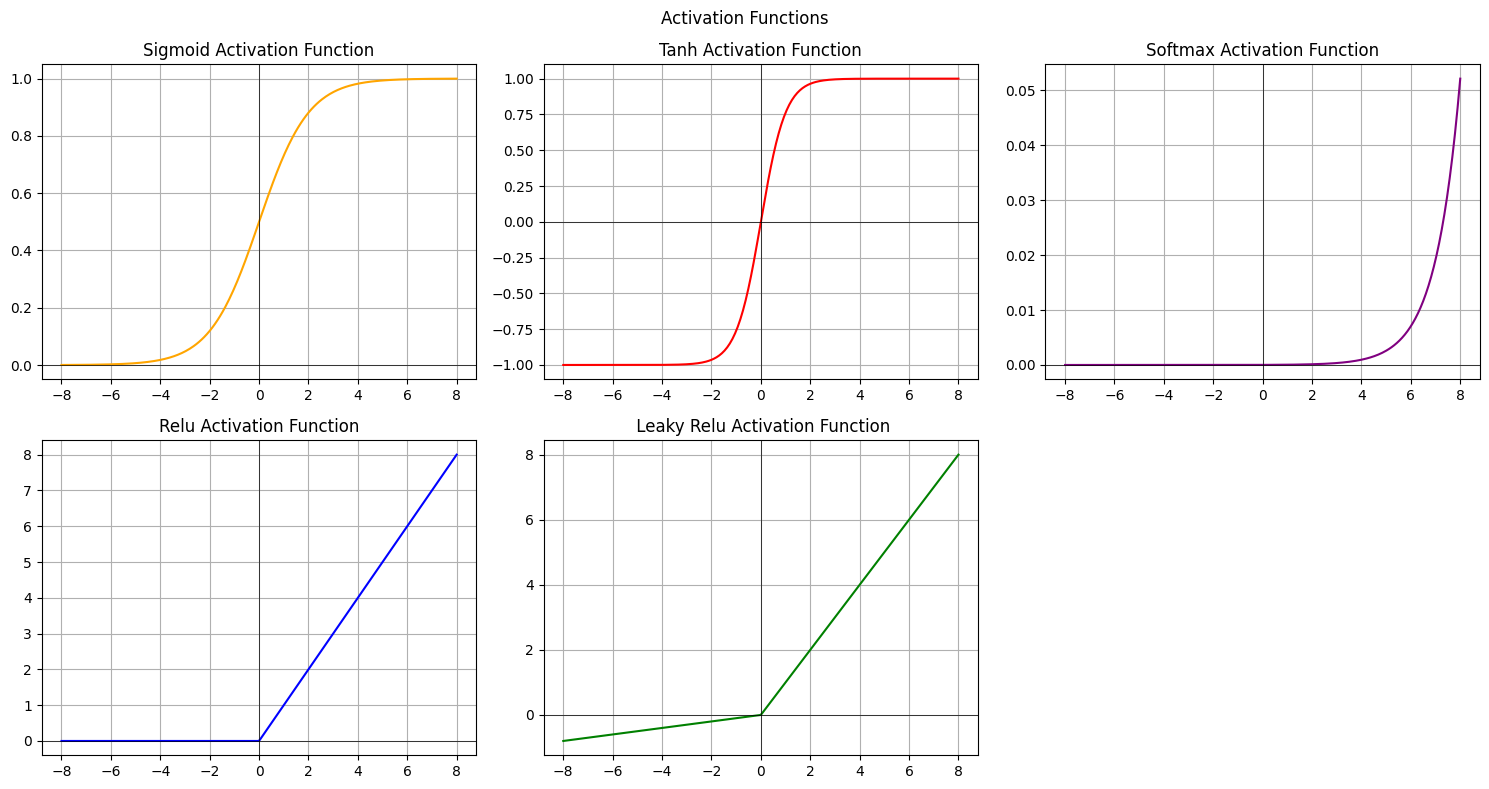

In [19]:
plot_all_activation_functions_separately(x)

In [20]:
def plot_all_activation_functions_together(x):
    plt.figure(figsize=(10 , 6))
    plt.plot(x , sigmoid_activation_function(x) , label="sigmoid" , color="orange")
    plt.plot(x , tanh_activation_function(x) , label="tanh" , color="red")
    plt.plot(x , softmax_activation_function(x) , label="softmax" , color="purple")
    plt.plot(x , relu_activation_function(x) , label="relu" , color="blue")
    plt.plot(x , leaky_relu_activation_function(x) , label="leaky_relu" , color="green")
    plt.title("All Activation Functions")
    plt.axhline(0 , color="black" , linewidth=0.5)
    plt.axvline(0 , color="black" , linewidth=0.5)
    plt.xlabel("x")
    plt.ylabel("fn(x)")
    plt.legend()
    plt.grid(True)
    plt.show()
    

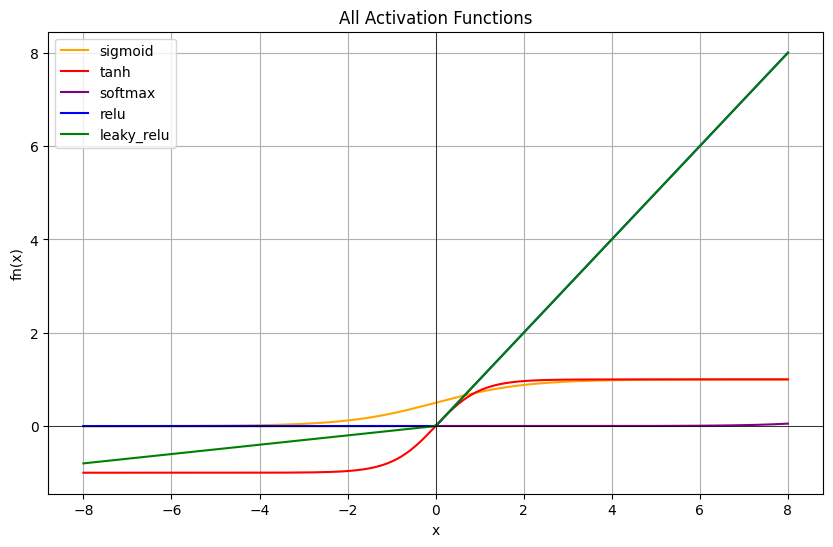

In [21]:
plot_all_activation_functions_together(x)

## *02> Effect on sample synthetic data*

In [32]:
X , y = make_classification(
    n_samples=200,
    n_features=1,
    n_informative=1,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.5,
    random_state=42
)

print(f"X type : {type(X)}")
print(f"y type : {type(y)}")

X type : <class 'numpy.ndarray'>
y type : <class 'numpy.ndarray'>


In [24]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).flatten()

In [26]:
# creating df
df = pd.DataFrame({'x': X_scaled, 'label': y})
df['sigmoid']     = sigmoid_activation_function(X_scaled)
df['tanh']        = tanh_activation_function(X_scaled)
df['relu']        = relu_activation_function(X_scaled)
df['leaky_relu']  = leaky_relu_activation_function(X_scaled)
df['softmax']     = softmax_activation_function(X_scaled)

In [27]:
df.head()

,x,label,sigmoid,tanh,relu,leaky_relu,softmax
0,-1.209704,0,0.229754,-0.836591,0.000000,-0.120970,0.000969
1,0.864353,1,0.703569,0.698494,0.864353,0.864353,0.007708
2,1.016238,1,0.734239,0.768330,1.016238,1.016238,0.008972
3,0.992047,1,0.729492,0.758234,0.992047,0.992047,0.008758
4,0.958649,1,0.722851,0.743674,0.958649,0.958649,0.008470


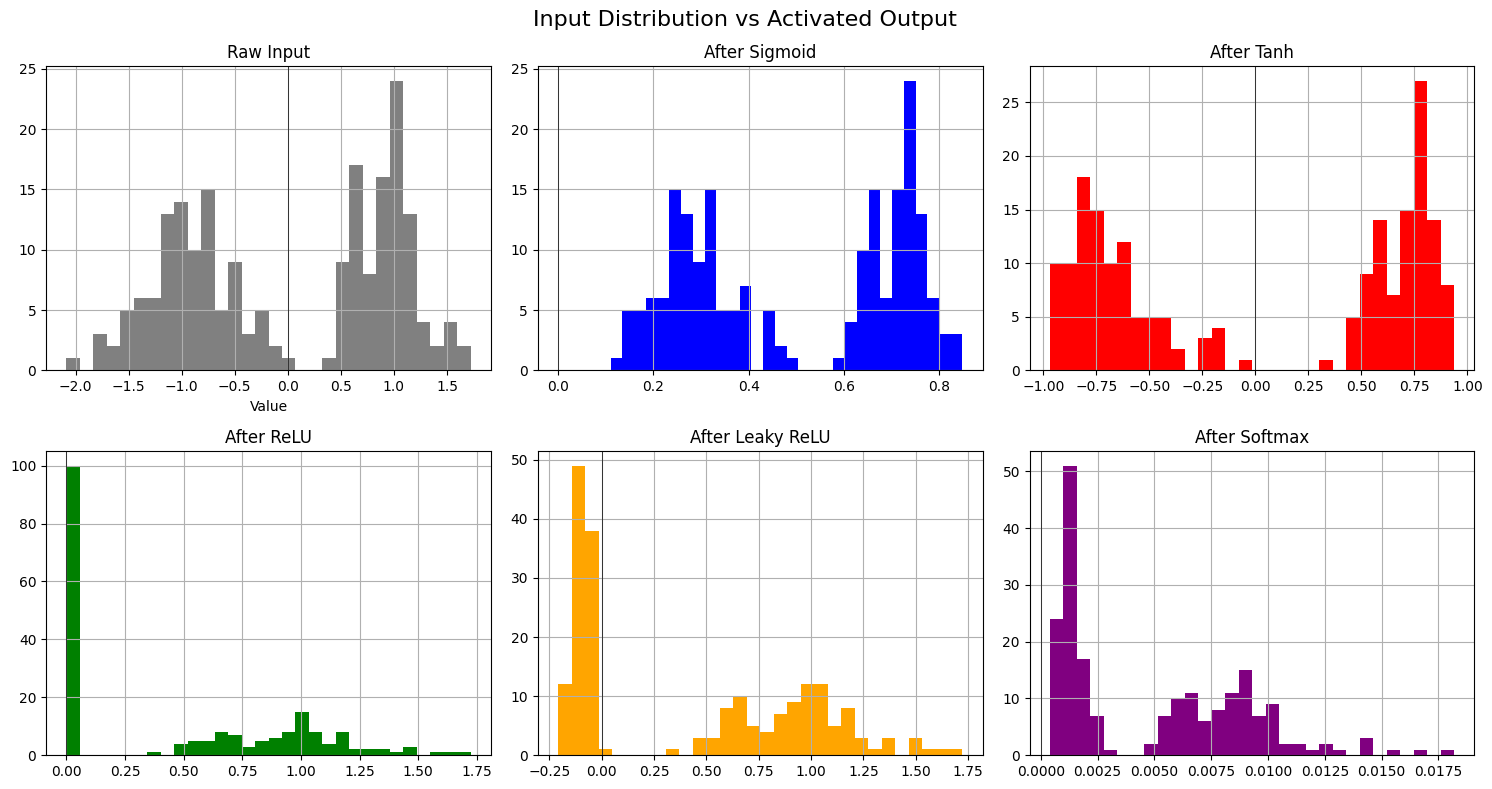

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle("Input Distribution vs Activated Output", fontsize=16)

axes[0][0].hist(X_scaled, bins=30, color='gray')
axes[0][0].set_title("Raw Input")
axes[0][0].axhline(0 , color="black" , linewidth=0.5)
axes[0][0].axvline(0 , color="black" , linewidth=0.5)
axes[0][0].grid(True)
axes[0][0].set_xlabel("Value")

axes[0][1].hist(df['sigmoid'], bins=30, color='blue')
axes[0][1].set_title("After Sigmoid")
axes[0][1].axhline(0 , color="black" , linewidth=0.5)
axes[0][1].axvline(0 , color="black" , linewidth=0.5)
axes[0][1].grid(True)

axes[0][2].hist(df['tanh'], bins=30, color='red')
axes[0][2].set_title("After Tanh")
axes[0][2].axhline(0 , color="black" , linewidth=0.5)
axes[0][2].axvline(0 , color="black" , linewidth=0.5)
axes[0][2].grid(True)

axes[1][0].hist(df['relu'], bins=30, color='green')
axes[1][0].set_title("After ReLU")
axes[1][0].axhline(0 , color="black" , linewidth=0.5)
axes[1][0].axvline(0 , color="black" , linewidth=0.5)
axes[1][0].grid(True)

axes[1][1].hist(df['leaky_relu'], bins=30, color='orange')
axes[1][1].set_title("After Leaky ReLU")
axes[1][1].axhline(0 , color="black" , linewidth=0.5)
axes[1][1].axvline(0 , color="black" , linewidth=0.5)
axes[1][1].grid(True)

axes[1][2].hist(df['softmax'], bins=30, color='purple')
axes[1][2].set_title("After Softmax")
axes[1][2].axhline(0 , color="black" , linewidth=0.5)
axes[1][2].axvline(0 , color="black" , linewidth=0.5)
axes[1][2].grid(True)

plt.tight_layout()
plt.show()

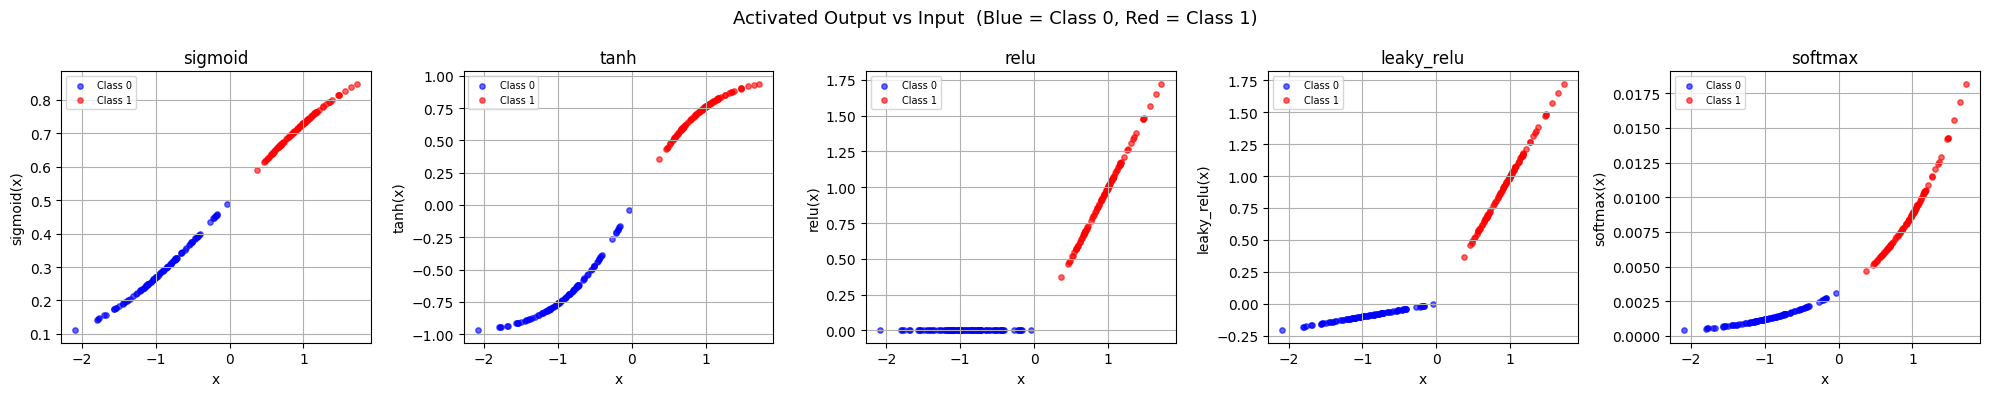

In [38]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Activated Output vs Input  (Blue = Class 0, Red = Class 1)", fontsize=13)

cols   = ['sigmoid', 'tanh', 'relu', 'leaky_relu', 'softmax']
colors_map = {0: 'blue', 1: 'red'}

for ax, col in zip(axes, cols):
    for cls in [0, 1]:
        mask = df['label'] == cls
        ax.scatter(df.loc[mask, 'x'], df.loc[mask, col],
                   c=colors_map[cls], s=15, alpha=0.6, label=f'Class {cls}')
    ax.set_title(col)
    ax.set_xlabel("x")
    ax.set_ylabel(f"{col}(x)")
    ax.legend(fontsize=7)
    ax.grid(True)

plt.tight_layout()
plt.show()